In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv('../data/raw/credit_card.csv')

In [3]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [4]:
df.shape

(6362620, 11)

In [5]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [7]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
step,6362620.0,NaN,NaN,NaN,243.397246,142.331971,1.0,156.0,239.0,335.0,743.0
type,6362620,5,CASH_OUT,2237500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,6362620.0,NaN,NaN,NaN,179861.903549,603858.231463,0.0,13389.57,74871.94,208721.4775,92445516.64
nameOrig,6362620,6353307,C2098525306,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceOrg,6362620.0,NaN,NaN,NaN,833883.104074,2888242.673038,0.0,0.0,14208.0,107315.175,59585040.37
newbalanceOrig,6362620.0,NaN,NaN,NaN,855113.668579,2924048.502954,0.0,0.0,0.0,144258.41,49585040.37
nameDest,6362620,2722362,C1286084959,113,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceDest,6362620.0,NaN,NaN,NaN,1100701.66652,3399180.112994,0.0,0.0,132705.665,943036.7075,356015889.35
newbalanceDest,6362620.0,NaN,NaN,NaN,1224996.398202,3674128.94212,0.0,0.0,214661.44,1111909.25,356179278.92
isFraud,6362620.0,NaN,NaN,NaN,0.001291,0.035905,0.0,0.0,0.0,0.0,1.0


In [8]:
df['isFraud'].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

Insights: 6,362,620 rows, 8,213 fraud (0.129%)

In [9]:
df['isFraud'].value_counts(normalize=True) * 100

isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64

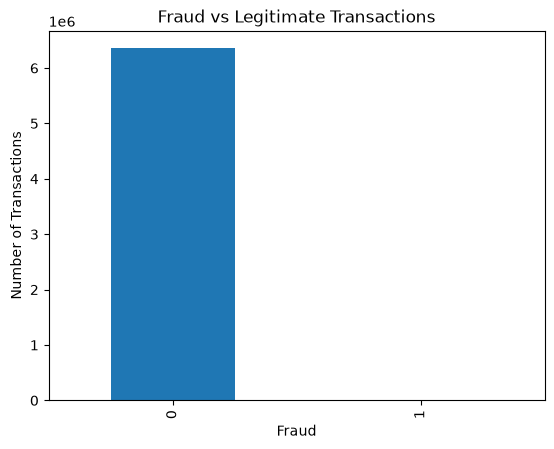

In [10]:
import matplotlib.pyplot as plt

df["isFraud"].value_counts().plot(kind="bar")

plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("Fraud")
plt.ylabel("Number of Transactions")
plt.show()

In [11]:
df.dtypes

step                int64
type                  str
amount            float64
nameOrig              str
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest              str
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object

In [12]:
missing = df.isnull().sum()
print(missing)

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df['step'].describe()

count    6.362620e+06
mean     2.433972e+02
std      1.423320e+02
min      1.000000e+00
25%      1.560000e+02
50%      2.390000e+02
75%      3.350000e+02
max      7.430000e+02
Name: step, dtype: float64

In [15]:
df["step"].nunique()

743

In [16]:
df["step"].min(), df["step"].max()

(np.int64(1), np.int64(743))

In [17]:
fraud_by_step = (
    df.groupby("step")["isFraud"]
    .agg(["count", "sum"])
    .rename(columns={"sum": "fraud_count"})
)

In [18]:
fraud_by_step["fraud_rate"] = (
    fraud_by_step["fraud_count"] /
    fraud_by_step["count"]
)

In [19]:

fraud_by_step.head()

,count,fraud_count,fraud_rate
step,,,
1,2708,16,0.005908
2,1014,8,0.007890
3,552,4,0.007246
4,565,10,0.017699
5,665,6,0.009023


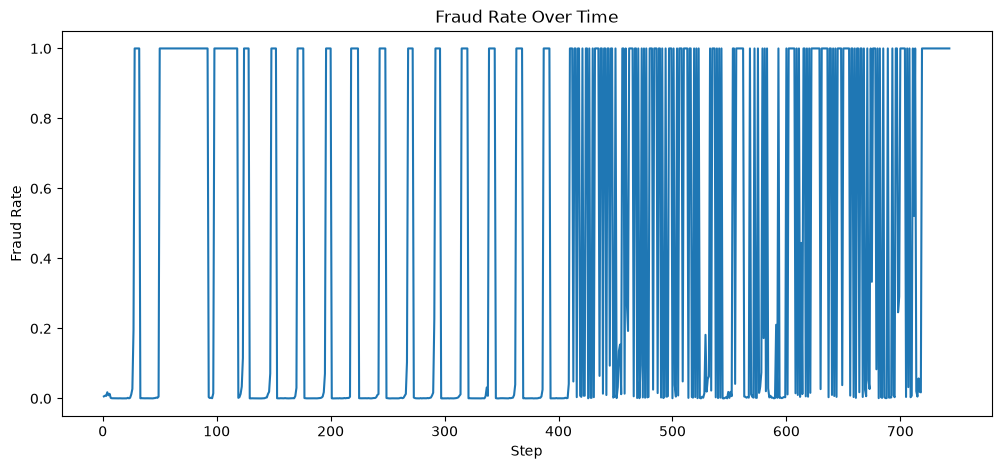

In [20]:
plt.figure(figsize=(12, 5))

plt.plot(
    fraud_by_step.index,
    fraud_by_step["fraud_rate"]
)

plt.xlabel("Step")
plt.ylabel("Fraud Rate")
plt.title("Fraud Rate Over Time")

plt.show()

In [ ]:
# Analyze fraud by transaction type
fraud_by_type = (
    df.groupby("type")["isFraud"]
    .agg(count="count", fraud_count="sum", fraud_rate="mean")
)
fraud_by_type

,count,fraud_count,fraud_rate
type,,,
CASH_IN,1399284,0,0.000000
CASH_OUT,2237500,4116,0.001840
DEBIT,41432,0,0.000000
PAYMENT,2151495,0,0.000000
TRANSFER,532909,4097,0.007688


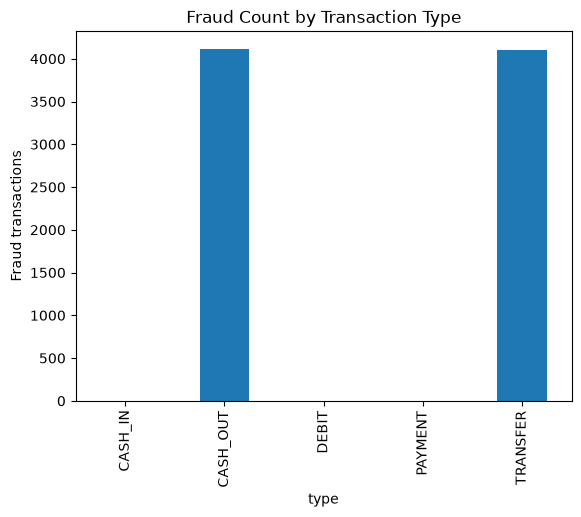

In [22]:
#Visualize fraud by transaction type
fraud_by_type["fraud_count"].plot(kind="bar")
plt.title("Fraud Count by Transaction Type")
plt.ylabel("Fraud transactions")
plt.show()

Insights : Fraud occurs only in TRANSFER (4,097) and CASH_OUT (4,116). The other three types have zero fraud

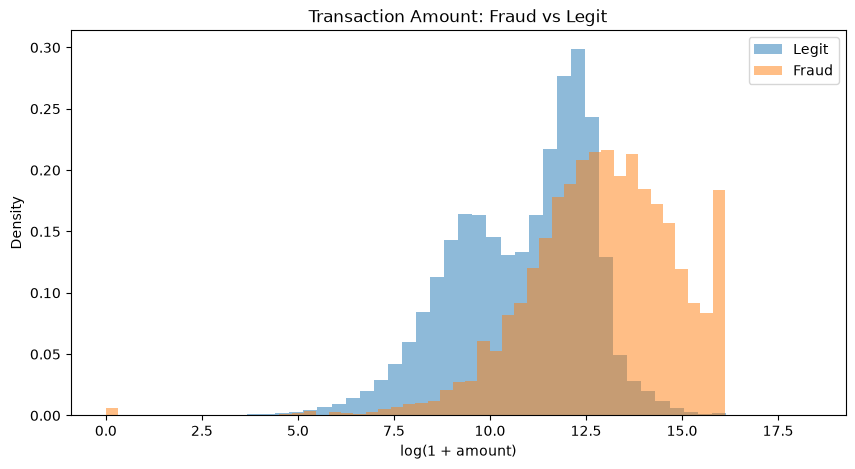

In [ ]:
#Amount , Fraud vs Legit(log scale)
plt.figure(figsize=(10, 5))
for label, name in [(0, "Legit"), (1, "Fraud")]:
    plt.hist(
        np.log1p(df.loc[df["isFraud"] == label, "amount"]),
        bins=50, alpha=0.5, density=True, label=name
    )
plt.xlabel("log(1 + amount)")
plt.ylabel("Density")
plt.title("Transaction Amount: Fraud vs Legit")
plt.legend()
plt.show()

In [ ]:
#amount summary statistics by fraud status
df.groupby("isFraud")["amount"].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,1.781970e+05,5.962370e+05,0.01,13368.395,74684.72,208364.76,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,127091.330,441423.44,1517771.48,10000000.00


Insights: Fraud amounts are much larger (median about 441k vs 75k for legit) and are capped at 10M

In [ ]:
#median balance (Fraud vs Legit)
bal_cols = ["oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
df.groupby("isFraud")[bal_cols].median()

,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
isFraud,,,,
0,14069.00,0.0,133311.8,214881.70
1,438983.45,0.0,0.0,4676.42


Insights: 98% zero balance finding is real, but note that 57% of legit rows also have newbalanceOrig == 0. On its own it’s a weak signal. It gets strong once you combine it with amount == oldbalanceOrg (account fully emptied) and the type filter


Insights: Fraud destinations have oldbalanceDest around 0 and a tiny newbalanceDest, which hints at balance inconsistencies. That’s what the engineered features below will capture.

In [ ]:
#How often origin account has made to Zero balance
fraud = df[df["isFraud"] == 1]
legit = df[df["isFraud"] == 0]

print("Fraud: newbalanceOrig == 0 ->", (fraud["newbalanceOrig"] == 0).mean())
print("Legit: newbalanceOrig == 0 ->", (legit["newbalanceOrig"] == 0).mean())

Fraud: newbalanceOrig == 0 -> 0.9805186898818946
Legit: newbalanceOrig == 0 -> 0.566774051457516


Insights : 98% times for the fraud data the origin account will have been made a zero balance

In [ ]:
#Do account name repeat?
print("rows:", len(df))
print("unique nameOrig:", df["nameOrig"].nunique())
print("unique nameDest:", df["nameDest"].nunique())

rows: 6362620
unique nameOrig: 6353307
unique nameDest: 2722362


Insights: nameOrig is almost entirely unique (6.35M of 6.36M), so it’s useless. Drop nameOrig and nameDest

In [30]:
pd.crosstab(df["isFlaggedFraud"], df["isFraud"])

isFraud,0,1
isFlaggedFraud,,
0,6354407,8197
1,0,16


Insights: isFlaggedFraud caught only 16 of 8,213 frauds. Drop it.